# Встреча 4. Остановка

**Легенда.** Сервис бронирования отелей добавил на главную блок **«Горящие предложения»**: скидочные варианты должны подтолкнуть к бронированию. В тест приходит около 6 000 новых пользователей в день, сплит 50/50, по 3 000 человек в группе. Единица рандомизации и анализа — пользователь, момент попадания в тест — первый заход на главную.

Продакт хочет смотреть результат **каждый день** и остановить тест, как только «стало значимо». Обычный z-тест этого не разрешает: он рассчитан на один взгляд в конце. Разбираем, сколько стоит подглядывание, какие планы делают его честным и как отчитаться о рано остановленном тесте. Итог — политика остановки для команды.

| Метрика | Роль | Что хотим |
| --- | --- | --- |
| Конверсия в бронирование | основная | рост, MDE +0.5 п.п. при базе 4.8% |
| Выручка на пользователя | основная | рост |
| Доля пользователей с отменой брони | контрольная (guardrail) | не вырасти |

**Правило решения.** Раскатываем, если значимо выросла хотя бы одна основная метрика, а контрольная значимо не ухудшилась. Основных метрик две, поэтому по Бонферрони каждая получает $\alpha$ = 2.5% (двусторонний). Контрольная в поправке не участвует: она не открывает раскатку, а только запрещает её.

Опираемся на работы Lan и DeMets (функции расхода $\alpha$), Johari, Pekelis и Walsh (always-valid inference, mSPRT), Jennison и Turnbull (условная мощность, binding и non-binding futility) и на книгу Kohavi, Tang, Xu о новизне и минимальной длительности. Полный список — в README встречи.

**Разделы**

1. Цена подглядывания.
2. Group sequential test: границы и запас выборки.
3. mSPRT и always-valid inference.
4. Futility: остановка за бесперспективностью.
5. Прогон лога по дням.
6. Завышение эффекта при ранней остановке и честный отчёт.
7. Решение для продакта.
8. Политика остановки.
9. Как было на самом деле.

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

### Библиотеки и план теста

Параметры, зафиксированные до запуска. Базовая конверсия — по истории сервиса.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F", "#DD8452"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
norm = stats.norm

ALPHA = 0.05                 # общий уровень на решение
ALPHA_PRIMARY = ALPHA / 2    # на каждую из двух основных метрик (Бонферрони), двусторонний
POWER = 0.80
P_BASE = 0.048               # конверсия по истории
MDE = 0.005                  # +0.5 п.п.
N_DAY = 3_000                # пользователей в группе за день
PLAN_DAYS = 14               # две полные недели
CAP = float(np.round(stats.lognorm.ppf(0.99, 1.2, scale=12_000), -3))  # порог выручки: 99-й перцентиль чека по истории (логнормаль, медиана 12 000 ₽, σ = 1.2)
P_CANCEL = 0.009             # доля пользователей с отменой по истории
DATA = Path("../data/hotdeals_segmented.csv")
LOOKS = np.arange(1, PLAN_DAYS + 1) / PLAN_DAYS   # ежедневные взгляды в долях плановой выборки


def drift_paths(looks, drift: float, n_paths: int, seed: int = 1) -> np.ndarray:
    """Пути z-статистики Z(t) = (W(t) + drift·t) / sqrt(t) в долях данных looks (drift — эффект в единицах Z при t = 1)."""
    looks = np.asarray(looks, dtype=float)
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks, prepend=0.0)
    walk = rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * np.sqrt(gaps) + drift * gaps
    return np.cumsum(walk, axis=1) / np.sqrt(looks)


def null_paths(looks, n_paths: int, seed: int = 11) -> np.ndarray:
    """Пути z-статистики при верной H0."""
    return drift_paths(looks, 0.0, n_paths, seed)

### Данные

Из-за заморозки релизов блок проработал не две недели, а **четыре**, поэтому в логе 28 дней. Сначала играем тест так, как он шёл бы в реальности: день за днём и только на **первых 14 днях** (`plan_logs`). Дни 15–28 откроем в разделе «Решение для продакта».

Одна строка — один пользователь. Нам нужны `date`, `group`, `booked`, `revenue`, `cancelled`; остальные колонки (устройство, новизна, активность) понадобятся на встрече 6. Функция `daily_cumulative(df, metric)` возвращает накопленные по дням `n_a`, `n_b`, `diff` (разность средних B − A) и `V` (дисперсию этой разности).

In [2]:
logs = pd.read_csv(DATA, parse_dates=["date"])
logs["day"] = (logs["date"] - logs["date"].min()).dt.days + 1
print(logs.shape, f"период: {logs['date'].min():%Y-%m-%d} ({logs['date'].min():%A}) — {logs['date'].max():%Y-%m-%d}")

plan_logs = logs[logs["day"] <= PLAN_DAYS]
counts = plan_logs["group"].value_counts().reindex(["A", "B"])
print(f"Дни 1–14: A {counts['A']:,}, B {counts['B']:,}, SRM p-value = {stats.chisquare(counts).pvalue:.3f}")
print(f"Пользователей в группе за день: {plan_logs.groupby(['day', 'group']).size().mean():,.0f}; "
      f"конверсия A: {plan_logs.loc[plan_logs['group'] == 'A', 'booked'].mean():.2%}")


def daily_cumulative(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    """Накопленные по дням размеры групп, разность средних и её дисперсия."""
    grouped = (df.assign(square=df[metric] ** 2).groupby(["day", "group"])
               .agg(n=(metric, "size"), total=(metric, "sum"), squares=("square", "sum")).unstack().cumsum())
    n_a, n_b = grouped[("n", "A")], grouped[("n", "B")]
    mean_a, mean_b = grouped[("total", "A")] / n_a, grouped[("total", "B")] / n_b
    var_a = grouped[("squares", "A")] / n_a - mean_a ** 2
    var_b = grouped[("squares", "B")] / n_b - mean_b ** 2
    return pd.DataFrame({"n_a": n_a, "n_b": n_b, "mean_a": mean_a, "mean_b": mean_b,
                         "diff": mean_b - mean_a, "V": var_a / n_a + var_b / n_b})


cum_conv = daily_cumulative(plan_logs, "booked")
plan_logs.head(3)

(168158, 13) период: 2026-09-07 (Monday) — 2026-10-04
Дни 1–14: A 41,958, B 42,027, SRM p-value = 0.812


Пользователей в группе за день: 2,999; конверсия A: 4.75%


,user_id,date,group,booked,revenue,cancelled,device,reg_date,tenure_days,is_new,orders_90d,segment,day
0,100000,2026-09-07,B,0,0,0,mobile,2026-03-08,183,0,2,mid,1
1,100001,2026-09-07,A,0,0,0,mobile,2026-08-27,11,1,1,low,1
2,100002,2026-09-07,B,0,0,0,web,2026-05-30,100,0,4,mid,1


Сплит держится (SRM нет), трафик — около 3 000 на группу в день, в выходные больше. Тест стартовал в понедельник.

## Цена подглядывания

Обычный тест держит $\alpha$ только при одном взгляде. Каждый дополнительный взгляд — ещё один шанс шуму пересечь порог.

Накопленная z-статистика при $H_0$ — случайное блуждание, нормированное на $\sqrt{t}$. Соседние дни сильно связаны:

$$
\mathrm{corr}(Z_s, Z_t) = \sqrt{s/t}
$$

Например, z-статистики 13-го и 14-го дня коррелируют на 0.96: второй взгляд почти повторяет первый.

**Вопрос.** Двухнедельный тест смотрят каждый день обычным z-тестом с $\alpha$ = 5%. Если бы 14 проверок были независимы, ошибка была бы $1 - 0.95^{14}$, около 51%. Реальная ошибка больше или меньше? И почему не помогает просто взять порог по Бонферрони, 0.05 / 14?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Меньше: около 22% (симуляция ниже). Накопленные статистики соседних дней сильно зависимы, поэтому 14 взглядов — это не 14 независимых шансов. Но и не один: ошибка всё равно вчетверо выше заявленной, и при бесконечном просмотре любое блуждание рано или поздно пересечёт порог.

Бонферрони держит ошибку, но считает проверки независимыми и поэтому слишком строг: ошибка уходит заметно ниже 5%, а мы платим лишней потерей мощности. Границы GST (следующий раздел) учитывают зависимость точно и тратят ровно заявленную $\alpha$.

</details>

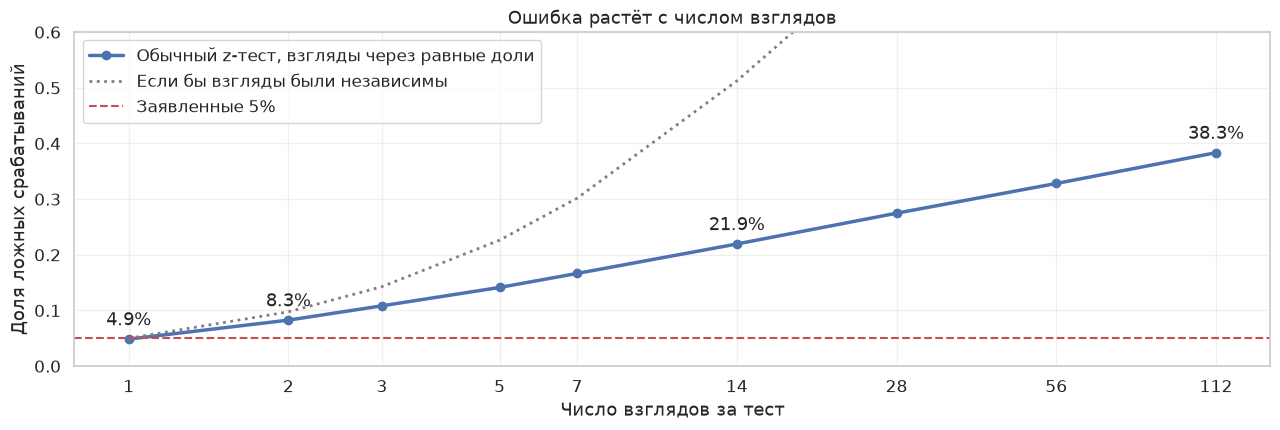

,1,2,3,5,7,14,28,56,112
FPR,0.049,0.083,0.108,0.141,0.166,0.219,0.275,0.328,0.383


In [3]:
looks_grid = np.array([1, 2, 3, 5, 7, 14, 28, 56, 112])
naive_fpr = [(np.abs(drift_paths(np.arange(1, k + 1) / k, 0.0, 100_000, seed=k)) > norm.ppf(0.975)).any(axis=1).mean()
             for k in looks_grid]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(looks_grid, naive_fpr, "-o", color=BLUE, linewidth=2.5, label="Обычный z-тест, взгляды через равные доли")
ax.plot(looks_grid, 1 - 0.95 ** looks_grid, ":", color=GRAY, linewidth=2, label="Если бы взгляды были независимы")
ax.axhline(0.05, color=RED, linestyle="--", linewidth=1.5, label="Заявленные 5%")
for k, v in zip(looks_grid, naive_fpr):
    if k in (1, 2, 14, 112):
        ax.annotate(f"{v:.1%}", (k, v), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set(xscale="log", xticks=looks_grid, xticklabels=looks_grid, ylim=(0, 0.6),
       xlabel="Число взглядов за тест", ylabel="Доля ложных срабатываний", title="Ошибка растёт с числом взглядов")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
pd.Series(naive_fpr, index=looks_grid, name="FPR").to_frame().T

* 2 взгляда — 8%, 14 ежедневных — 22%, 112 (каждые три часа) — 38%. Здесь $\alpha$ = 5%, как у обычного теста «на глаз». В нашем плане на метрику $\alpha$ = 2.5%, и при ежедневном взгляде ошибка к 14-му дню — 12% (раздел про mSPRT).
* Независимые проверки дали бы 51% уже при 14 взглядах: зависимость спасает, но не до 5%.

Та же проверка на нашем расписании, но уже на биномиальных конверсиях: 3 000 пользователей в группе в день, конверсия 4.8%, обычный z-тест с объединённой долей на днях из `look_days`. Функция возвращает долю A/A-тестов, значимых **хотя бы на одном** взгляде.

In [4]:
def peeking_fpr(look_days, p: float = P_BASE, n_day: int = N_DAY, R: int = 100_000,
                alpha: float = ALPHA, seed: int = 1) -> float:
    rng = np.random.default_rng(seed)
    look_days = np.asarray(look_days)
    days = look_days.max()
    x_a = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    x_b = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    n = n_day * look_days
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return float((np.abs(z) > norm.ppf(1 - alpha / 2)).any(axis=1).mean())

In [5]:
one_look = peeking_fpr([PLAN_DAYS])
daily = peeking_fpr(np.arange(1, PLAN_DAYS + 1))
print(f"Один взгляд: {one_look:.3f}, каждый день: {daily:.3f}")

Один взгляд: 0.050, каждый день: 0.218


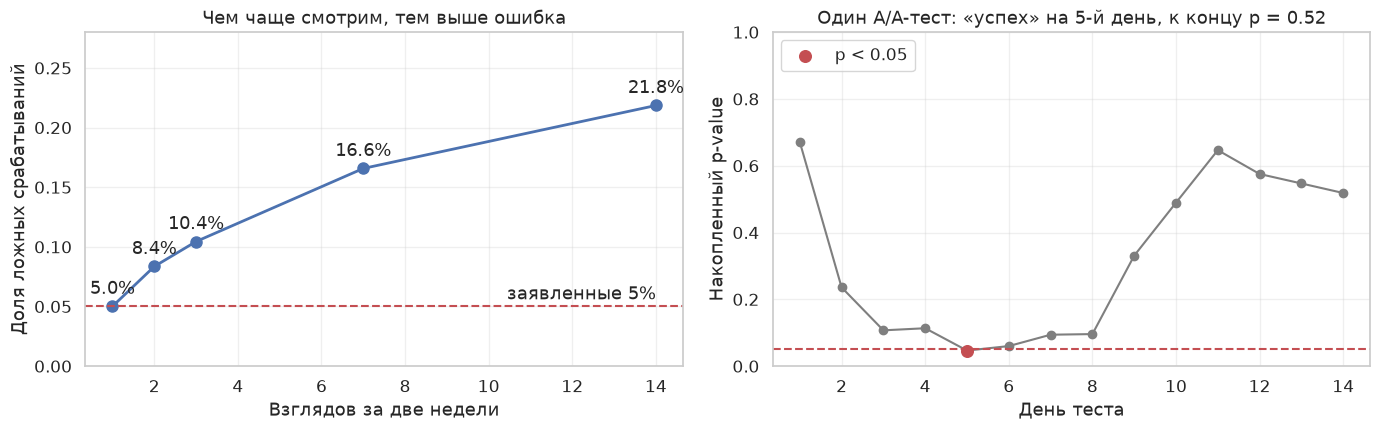

,1,2,3,7,14
Ложных срабатываний,0.050,0.084,0.104,0.166,0.218


In [6]:
schedules = {1: [14], 2: [7, 14], 3: [5, 10, 14], 7: [2, 4, 6, 8, 10, 12, 14], 14: list(range(1, 15))}
fpr_by_looks = pd.Series({k: peeking_fpr(days) for k, days in schedules.items()}, name="Ложных срабатываний")


def aa_pvalues(seed: int) -> np.ndarray:
    """Накопленный p-value одного A/A-теста по дням."""
    rng = np.random.default_rng(seed)
    x_a, x_b = (rng.binomial(N_DAY, P_BASE, PLAN_DAYS).cumsum() for _ in range(2))
    n = N_DAY * np.arange(1, PLAN_DAYS + 1)
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return 2 * norm.sf(np.abs(z))


example = next(s for s in range(1000) if (aa_pvalues(s) < ALPHA).any() and aa_pvalues(s)[-1] > 0.5)
path = aa_pvalues(example)
first_hit = int(np.argmax(path < ALPHA)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(fpr_by_looks.index, fpr_by_looks.values, "-o", color=BLUE, linewidth=2, markersize=8)
axes[0].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[0].text(14, ALPHA + 0.006, "заявленные 5%", ha="right")
for k, v in fpr_by_looks.items():
    axes[0].annotate(f"{v:.1%}", (k, v), textcoords="offset points", xytext=(0, 9), ha="center")
axes[0].set(xlabel="Взглядов за две недели", ylabel="Доля ложных срабатываний", ylim=(0, 0.28),
            title="Чем чаще смотрим, тем выше ошибка")
days = np.arange(1, PLAN_DAYS + 1)
axes[1].plot(days, path, "-o", color=GRAY, linewidth=1.5)
axes[1].scatter(days[path < ALPHA], path[path < ALPHA], color=RED, s=70, zorder=3, label="p < 0.05")
axes[1].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Накопленный p-value", ylim=(0, 1),
            title=f"Один A/A-тест: «успех» на {first_hit}-й день, к концу p = {path[-1]:.2f}")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()
fpr_by_looks.to_frame().T

Ежедневный взгляд в обычный тест даёт около 22% ложных срабатываний вместо 5%: один ложный запуск на пять тестов без эффекта. Даже два взгляда дают 8%. В симуляции трафик постоянный, 3 000 в день; в данных выходные выше. Картину это почти не меняет: ошибку определяют доли информации на взглядах, а не размер отдельного дня.

Справа — один такой A/A-тест (подобран для иллюстрации): «значимо» на 5-й день, а к концу p-value больше 0.5. Ложный «успех» обычно ранний: в первые дни оценка самая шумная. Команда, остановившаяся на 5-й день, не узнает, что к 14-му дню p-value вернулся бы к большим значениям.

## Group sequential test: границы и запас выборки

GST заранее делит бюджет $\alpha$ между взглядами. Функция расхода $\alpha(t)$ задаёт, сколько ошибки **накоплено** к доле данных $t$. Граница $b_i$ для $|Z|$ на взгляде $i$ подбирается так, чтобы потратить ровно прирост $\alpha(t_i) - \alpha(t_{i-1})$ с учётом зависимости взглядов.

Две классические функции в форме Lan-DeMets. O'Brien-Fleming почти ничего не тратит в начале и бережёт $\alpha$ на конец:

$$
\alpha_{OBF}(t) = 2 \left(1 - \Phi\left(\frac{z_{1-\alpha/2}}{\sqrt{t}}\right)\right)
$$

Pocock тратит равномерно:

$$
\alpha_{P}(t) = \alpha \log(1 + (e - 1) t)
$$

Границы считаем симуляцией: генерируем миллион нулевых путей, на каждом взгляде отрезаем нужную долю самых больших $|Z|$ среди ещё не остановившихся путей. Если на эту долю приходится меньше 100 путей, берём границу аналитически. Мощность — доля путей со сносом, которые хоть раз прошли границу.

In [7]:
def obf_spending(t, alpha):
    """O'Brien-Fleming в форме Lan-DeMets."""
    return 2 * norm.sf(norm.ppf(1 - alpha / 2) / np.sqrt(t))


def pocock_spending(t, alpha):
    """Pocock в форме Lan-DeMets."""
    return alpha * np.log(1 + (np.e - 1) * t)


def gst_boundaries(spending, looks, alpha: float = ALPHA_PRIMARY,
                   n_paths: int = 1_000_000, seed: int = 11) -> np.ndarray:
    looks = np.asarray(looks, dtype=float)
    z = np.abs(null_paths(looks, n_paths, seed))
    alive = np.ones(n_paths, dtype=bool)
    spent, bounds = 0.0, []
    for i, t in enumerate(looks):
        step = float(spending(t, alpha)) - spent
        spent += step
        values = z[alive, i]
        k = int(step * n_paths)
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step / 2)
        bounds.append(bound)
        alive[alive] = values < bound
    return np.array(bounds)


def gst_power(boundaries, looks, drift: float, n_paths: int = 200_000, seed: int = 5) -> tuple:
    looks = np.asarray(looks, dtype=float)
    z = drift_paths(looks, drift, n_paths, seed)
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    first = np.where(fired, hits.argmax(axis=1), len(looks) - 1)
    return float(fired.mean()), float(looks[first].mean())


def inflation_factor(boundaries, looks, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    """Запас R, при котором мощность GST при MDE равна заданной."""
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return brentq(lambda r: gst_power(boundaries, looks, z_sum * np.sqrt(r))[0] - power, 1.0, 1.6, xtol=1e-3)

Сверим симуляцию с табличными границами O'Brien-Fleming (5 равных взглядов, двусторонний $\alpha$ = 5%) и проверим ошибку на свежих путях, которые не участвовали в подборе границ:

In [8]:
reference = np.array([4.877, 3.357, 2.680, 2.290, 2.031])
per_side = lambda t, a: 2 * obf_spending(t, a / 2)
ours = gst_boundaries(per_side, np.arange(1, 6) / 5, alpha=0.05)
print("Таблица:  ", reference)
print("Симуляция:", ours.round(3))

BOUNDS_OBF = gst_boundaries(obf_spending, LOOKS)
BOUNDS_POCOCK = gst_boundaries(pocock_spending, LOOKS)
fresh = np.abs(null_paths(LOOKS, 1_000_000, seed=99))
fpr_obf, fpr_pocock = ((fresh >= b).any(axis=1).mean() for b in (BOUNDS_OBF, BOUNDS_POCOCK))
R_OBF = inflation_factor(BOUNDS_OBF, LOOKS)
R_POCOCK = inflation_factor(BOUNDS_POCOCK, LOOKS)
print(f"Ложных срабатываний на новых путях: O'Brien-Fleming {fpr_obf:.4f}, Pocock {fpr_pocock:.4f} при цели {ALPHA_PRIMARY}")
print(f"Запас выборки: O'Brien-Fleming {R_OBF:.3f}, Pocock {R_POCOCK:.3f}")

Таблица:   [4.877 3.357 2.68  2.29  2.031]
Симуляция: [4.877 3.358 2.682 2.291 2.031]


Ложных срабатываний на новых путях: O'Brien-Fleming 0.0246, Pocock 0.0245 при цели 0.025
Запас выборки: O'Brien-Fleming 1.048, Pocock 1.244


**Запас выборки.** Строгие ранние границы съедают немного мощности. Чтобы её вернуть, максимальную выборку увеличивают: $N_{max} = R \cdot n_{fixed}$. Запас $R$ выше подобран так, чтобы мощность при MDE снова была 80%. Соберём план: сколько нужно пользователей при каждом методе и сколько в среднем потратим.

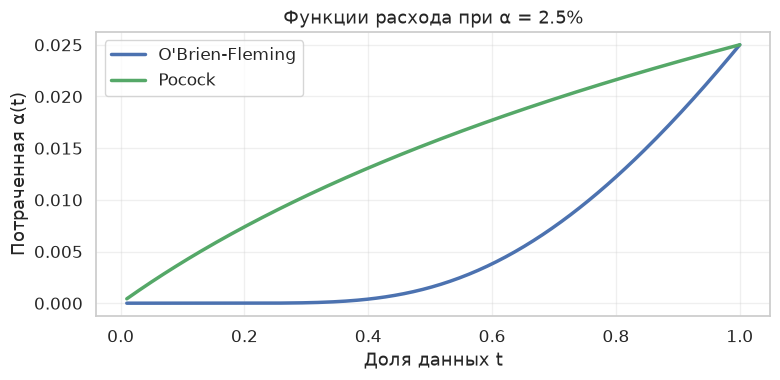

In [9]:
t_fine = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_fine, obf_spending(t_fine, ALPHA_PRIMARY), color=BLUE, linewidth=2.5, label="O'Brien-Fleming")
ax.plot(t_fine, pocock_spending(t_fine, ALPHA_PRIMARY), color=GREEN, linewidth=2.5, label="Pocock")
ax.set(xlabel="Доля данных t", ylabel="Потраченная α(t)", title="Функции расхода при α = 2.5%")
ax.legend()
plt.tight_layout()
plt.show()

Фиксированный тест: 36,456 на группу, 12.2 дня


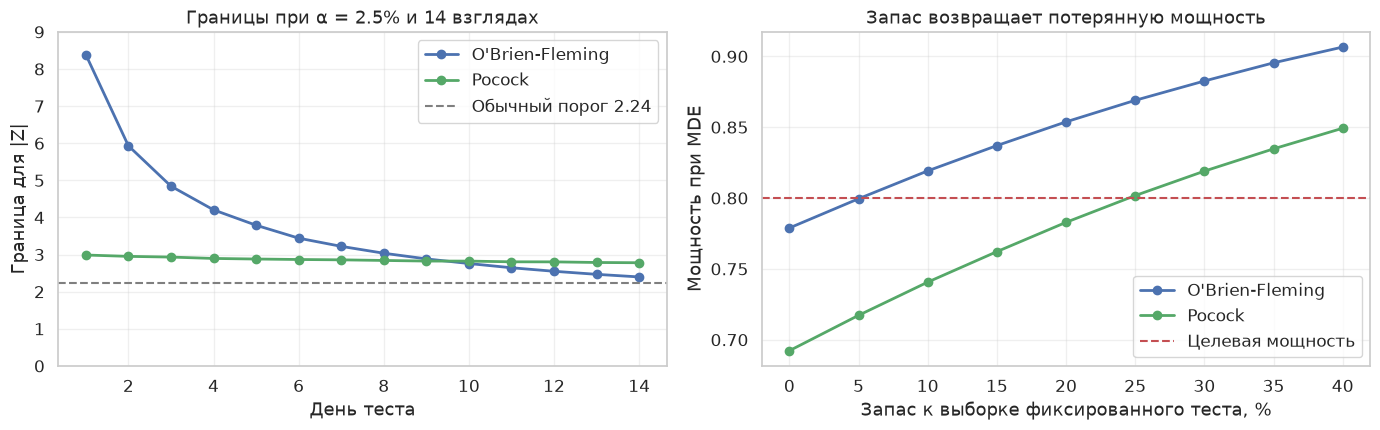

                   1     7     14
O'Brien-Fleming 8.390 3.220 2.400
Pocock          2.990 2.860 2.780


,Запас R,Nmax на группу,Дней до Nmax,"E[n] при H0, % от fixed","E[n] при MDE, % от fixed","E[n] при 1.5 MDE, % от fixed"
Фиксированный тест,1.000,"36,456.000",12.152,100.000,100.000,100.000
"GST, O'Brien-Fleming",1.048,"38,209.000",12.736,104.319,79.132,56.121
"GST, Pocock",1.244,"45,365.000",15.122,122.799,78.948,45.072


In [10]:
def fixed_n(mde: float, p: float = P_BASE, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    """Размер группы фиксированного теста для конверсии."""
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return z_sum ** 2 * (p * (1 - p) + (p + mde) * (1 - p - mde)) / mde ** 2


n_fixed = fixed_n(MDE)
z_sum = norm.ppf(1 - ALPHA_PRIMARY / 2) + norm.ppf(POWER)
rows = {}
for name, bounds, r in [("Фиксированный тест", np.array([norm.ppf(1 - ALPHA_PRIMARY / 2)]), 1.0),
                        ("GST, O'Brien-Fleming", BOUNDS_OBF, R_OBF),
                        ("GST, Pocock", BOUNDS_POCOCK, R_POCOCK)]:
    grid = LOOKS if len(bounds) > 1 else np.array([1.0])
    shares = [gst_power(bounds, grid, z_sum * np.sqrt(r) * eff)[1] for eff in (0.0, 1.0, 1.5)]
    rows[name] = {"Запас R": r, "Nmax на группу": round(n_fixed * r), "Дней до Nmax": n_fixed * r / N_DAY,
                  "E[n] при H0, % от fixed": 100 * r * shares[0], "E[n] при MDE, % от fixed": 100 * r * shares[1],
                  "E[n] при 1.5 MDE, % от fixed": 100 * r * shares[2]}
plan = pd.DataFrame(rows).T
print(f"Фиксированный тест: {n_fixed:,.0f} на группу, {n_fixed / N_DAY:.1f} дня")

grid_r = np.linspace(1.0, 1.4, 9)
power_obf = [gst_power(BOUNDS_OBF, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]
power_pocock = [gst_power(BOUNDS_POCOCK, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(days, BOUNDS_OBF, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[0].plot(days, BOUNDS_POCOCK, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[0].axhline(norm.ppf(1 - ALPHA_PRIMARY / 2), color=GRAY, linestyle="--", linewidth=1.5,
                label=f"Обычный порог {norm.ppf(1 - ALPHA_PRIMARY / 2):.2f}")
axes[0].set(xlabel="День теста", ylabel="Граница для |Z|", ylim=(0, 9), title="Границы при α = 2.5% и 14 взглядах")
axes[0].legend()
axes[1].plot(100 * (grid_r - 1), power_obf, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[1].plot(100 * (grid_r - 1), power_pocock, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[1].axhline(POWER, color=RED, linestyle="--", linewidth=1.5, label="Целевая мощность")
axes[1].set(xlabel="Запас к выборке фиксированного теста, %", ylabel="Мощность при MDE",
            title="Запас возвращает потерянную мощность")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"O'Brien-Fleming": BOUNDS_OBF, "Pocock": BOUNDS_POCOCK}, index=days).loc[[1, 7, 14]].T.round(2))
plan

* **O'Brien-Fleming:** граница 8.4 в первый день и 3.2 на конец первой недели — рано остановиться можно только при огромном эффекте. Последняя граница 2.40, почти обычный порог 2.24. Запас около 5%, и при эффекте, равном MDE, тест тратит в среднем ~80% выборки фиксированного.
* **Pocock:** границы ~2.8 почти на всех взглядах, запас ~25%. Выигрыш по средней выборке он даёт только при сильном эффекте (1.5 MDE).
* **Цена страховки при $H_0$:** если эффекта нет, GST тратит всю $N_{max}$ — больше фиксированного теста: ~104% у O'Brien-Fleming и ~123% у Pocock. Это решает futility (раздел 4).

Выбираем **O'Brien-Fleming**. Выборку округляем вверх до целых недель: 12.7 дня превращаются в 14, $N_{max}$ = 42 000 на группу. Pocock потребовал бы 15.1 дня — уже три недели.

**Вопрос.** Продакт спрашивает: «Pocock же разрешает остановиться раньше — почему не он?»

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Pocock тратит $\alpha$ равномерно, поэтому ранние границы ниже, но последняя выше обычной (~2.8 против 2.24 у фиксированного теста). Цена — +25% к максимальной выборке и лишняя неделя календаря. Если эффекта нет, Pocock тратит 123% фиксированной выборки. Выигрыш есть только при эффекте заметно больше MDE, а на таких эффектах O'Brien-Fleming тоже останавливается рано.

Есть и продуктовая причина: ранняя остановка при Pocock чаще приходится на первые дни, когда эффект завышен новизной и шумом (раздел 6).

</details>

In [11]:
N_MAX = PLAN_DAYS * N_DAY
SIGMA2_DIFF = P_BASE * (1 - P_BASE) + (P_BASE + MDE) * (1 - P_BASE - MDE)
V_PLAN = SIGMA2_DIFF / N_MAX
THETA_MDE = MDE / np.sqrt(V_PLAN)         # снос при эффекте MDE в единицах Z на Nmax
power_plan = gst_power(BOUNDS_OBF, LOOKS, THETA_MDE)[0]
print(f"Nmax = {N_MAX:,} на группу, две полные недели. Снос при MDE θ = {THETA_MDE:.2f}, "
      f"мощность O'Brien-Fleming: {power_plan:.3f}")

Nmax = 42,000 на группу, две полные недели. Снос при MDE θ = 3.31, мощность O'Brien-Fleming: 0.839


**Вопрос.** Аналитик заболел и пропустил взгляд на 5-й день, а в выходные трафик на четверть выше будних. Ломает ли это план с границами, посчитанными для 14 равных взглядов?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет, если считать границы через функцию расхода. В форме Lan-DeMets граница зависит не от номера взгляда, а от **фактической доли информации** $t = (n_A + n_B) / (2N_{max})$. Пропущенный взгляд просто не тратит свой кусок $\alpha$: на следующем взгляде граница считается по приросту $\alpha(t)$ с прошлого фактического взгляда. Неравные дни сдвигают доли $t$, и границы пересчитываются по ним. Так мы и сделаем на логе (раздел 5): доли там фактические, на последнем взгляде тратится весь остаток $\alpha$.

Ломает план другое: менять функцию расхода или $N_{max}$ после того, как увидели данные, и добавлять взгляды «по настроению», не записывая их.

</details>

## mSPRT и always-valid inference

GST требует заранее зафиксировать $N_{max}$. mSPRT (mixture sequential probability ratio test) не требует ни расписания, ни $N_{max}$: always-valid p-value и доверительная последовательность корректны в **любой** момент, сколько бы раз мы ни смотрели и как бы долго ни продлевали тест. Платим шириной интервала и мощностью.

Статистика — отношение правдоподобий, усреднённое по эффектам $\Delta$ из нормального распределения со средним 0 и дисперсией $\tau^2$. Пусть $\bar\Delta$ — оценка разности, $V$ — её дисперсия. Тогда

$$
\log \Lambda = \frac{1}{2} \log \frac{V}{V + \tau^2} + \frac{\bar\Delta^2 \tau^2}{2V(V + \tau^2)}
$$

Always-valid p-value — накопленный минимум: $p_n = \min(p_{n-1}, 1/\Lambda_n)$, $p_0 = 1$. При $H_0$ $\Lambda_n$ — мартингал со средним 1, поэтому по неравенству Вилля вероятность хоть когда-нибудь дойти до $1/\alpha$ не больше $\alpha$. Отсюда «always valid».

Полуширина доверительной последовательности ($\bar\Delta \pm r$ накрывает эффект одновременно на всех днях):

$$
r^2 = \frac{2V(V + \tau^2)}{\tau^2} \left(\log \frac{1}{\alpha} + \frac{1}{2} \log \frac{V + \tau^2}{V}\right)
$$

**Выбор $\tau$.** $\tau$ фиксируется в плане, до запуска: так, чтобы ширина была минимальна там, где мы рассчитываем принимать решение, при плановом $V_{plan}$:

$$
\tau^2 \approx c \cdot V_{plan}
$$

$$
c = -2 \log \alpha + \log(1 - 2 \log \alpha)
$$

**Вопрос.** В документации платформ экспериментов часто пишут: «$\tau$ берите около ожидаемого эффекта». Как это связано с формулой $\tau^2 \approx c \cdot V_{plan}$?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Подставим плановую дисперсию фиксированного теста: $V_{plan}$ — это дисперсия разности $\sigma^2$, делённая на $n_{fixed}$, а $n_{fixed}$ — это $(z_{1-\alpha/2} + z_{1-\beta})^2 \sigma^2 / \delta^2$. Получится

$$
\tau^2 \approx \frac{c \cdot \delta^2}{(z_{1-\alpha/2} + z_{1-\beta})^2}
$$

При $\alpha$ = 2.5% и мощности 80% и $c$, и квадрат суммы квантилей равны 9.50, поэтому $\tau \approx \delta$ (ячейка ниже даёт отношение 1.000). Это совпадение обычных $\alpha$ и $\beta$, а не закон, но оно объясняет правило: выбрать $\tau$ = MDE — значит настроить тест на выборку фиксированного теста. Мы настраиваем на $N_{max}$, она чуть больше, поэтому наш $\tau$ чуть меньше MDE.

</details>

In [12]:
def msprt_log_lambda(diff, V, tau: float):
    return 0.5 * np.log(V / (V + tau ** 2)) + diff ** 2 * tau ** 2 / (2 * V * (V + tau ** 2))


def msprt_radius(V, tau: float, alpha: float = ALPHA_PRIMARY):
    return np.sqrt(2 * V * (V + tau ** 2) / tau ** 2 * (np.log(1 / alpha) + 0.5 * np.log((V + tau ** 2) / V)))


def always_valid_p(diff, V, tau: float) -> np.ndarray:
    """Always-valid p-value: накопленный минимум 1 / Λ."""
    return np.minimum.accumulate(np.minimum(1.0, np.exp(-msprt_log_lambda(diff, V, tau))))


def tau_from_plan(V_plan: float, alpha: float = ALPHA_PRIMARY) -> float:
    """τ, минимизирующий ширину последовательности при плановом V."""
    c = -2 * np.log(alpha) + np.log(1 - 2 * np.log(alpha))
    return float(np.sqrt(c * V_plan))


TAU = tau_from_plan(V_PLAN)
tau_grid = np.geomspace(0.05, 20, 4000) * np.sqrt(V_PLAN)
tau_exact = tau_grid[np.argmin(msprt_radius(V_PLAN, tau_grid))]
print(f"τ по формуле: {TAU:.5f}, численный минимум ширины: {tau_exact:.5f}")
print(f"τ / MDE при n = n_fixed: {tau_from_plan(SIGMA2_DIFF / n_fixed) / MDE:.3f}")

τ по формуле: 0.00466, численный минимум ширины: 0.00472
τ / MDE при n = n_fixed: 1.000


**Вопрос.** Тест спланирован на 14 дней, но продакт просит «ещё пару недель» и продолжает смотреть каждый день. Что станет с ошибкой у обычного теста, у GST (после дня 14 — та же последняя граница) и у mSPRT?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Ячейка ниже считает это при $H_0$ с $\alpha$ = 2.5%.

* **Обычный тест** к 14-му дню ошибается в 12% случаев, к 28-му — в 16%.
* **GST** держит 2.5% ровно до $N_{max}$: к этому моменту весь бюджет $\alpha$ потрачен. При продлении с последней границей ошибка снова растёт: 5.6% к 28-му дню.
* **mSPRT** не выходит за 2.5% никогда, сколько ни продлевай: гарантия не зависит от горизонта.

Поэтому для GST правило жёсткое: за $N_{max}$ не выходим. Если тест всё же продлили, результат после $N_{max}$ — разведочный.

</details>

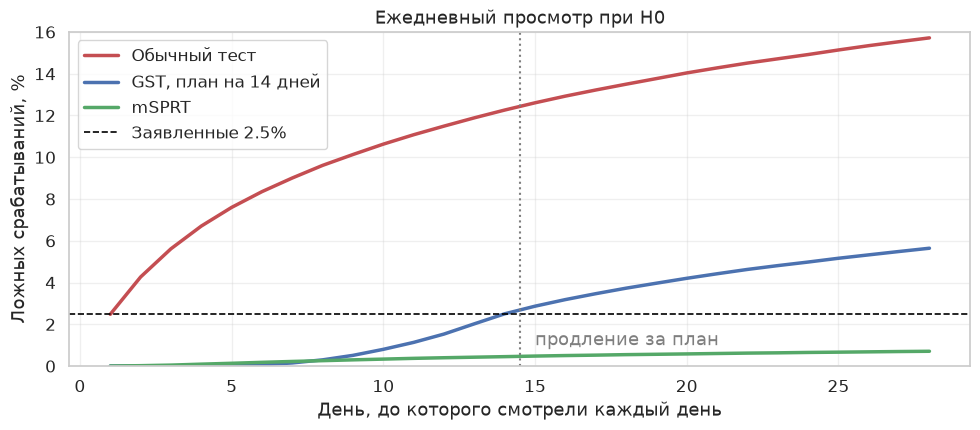

,7,14,21,28
Обычный тест,0.090,0.123,0.143,0.157
"GST, план на 14 дней",0.001,0.025,0.044,0.056
mSPRT,0.002,0.004,0.006,0.007


In [13]:
days28 = np.arange(1, 29)
t28 = days28 / PLAN_DAYS
z = drift_paths(t28, 0.0, 300_000, seed=3)
naive = np.abs(z) >= norm.ppf(1 - ALPHA_PRIMARY / 2)
gst = np.abs(z) >= np.r_[BOUNDS_OBF, np.full(14, BOUNDS_OBF[-1])]   # после дня 14 повторяем последнюю границу
msprt = msprt_log_lambda(z / np.sqrt(t28), 1 / t28, TAU / np.sqrt(V_PLAN)) >= np.log(1 / ALPHA_PRIMARY)
cumulative = pd.DataFrame({name: np.maximum.accumulate(hits, axis=1).mean(axis=0)
                           for name, hits in [("Обычный тест", naive), ("GST, план на 14 дней", gst), ("mSPRT", msprt)]},
                          index=days28)

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in zip(cumulative.columns, (RED, BLUE, GREEN)):
    ax.plot(days28, 100 * cumulative[name], color=color, linewidth=2.5, label=name)
ax.axhline(100 * ALPHA_PRIMARY, color="black", linestyle="--", linewidth=1.2, label="Заявленные 2.5%")
ax.axvline(14.5, color=GRAY, linestyle=":", linewidth=1.5)
ax.text(15, 1, "продление за план", color=GRAY)
ax.set(xlabel="День, до которого смотрели каждый день", ylabel="Ложных срабатываний, %", ylim=(0, 16),
       title="Ежедневный просмотр при H0")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
cumulative.loc[[7, 14, 21, 28]].T

mSPRT при ежедневных взглядах ещё и консервативен: 0.4% к 14-му дню при заявленных 2.5%. Гарантия рассчитана на просмотр после **каждого** наблюдения, а мы смотрим раз в день.

**Вопрос.** За свободу смотреть когда угодно mSPRT чем-то платит. Чем именно, и где тогда его место, если для решения о раскатке у нас уже есть GST?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Платит шириной и мощностью (ячейка ниже). Интервал mSPRT шире обычного всегда: в лучшей точке, около плановой выборки, в 1.46 раза. Мощность при MDE за те же 14 дней — около 58% против 84% у GST. Эту цену настройкой $\tau$ не убрать, можно только выбрать, где её минимизировать.

Отсюда разделение ролей:

* $N_{max}$ известен, данные раз в день, продлевать не нужно — **GST**, O'Brien-Fleming с запасом. Это решение о раскатке.
* Длительность неизвестна, тест могут продлить — **mSPRT** с $\tau$ из плана.
* Нужно быстро ловить вред (guardrail, выкатка релиза) — **mSPRT, смотрим каждый день**: горизонт не важен, важно не пропустить вред и не нарваться на ложную тревогу от подглядывания. Первый взгляд — когда наберётся достаточно событий (раздел 7).

Поэтому дальше конверсию и выручку решаем через GST, а guardrail по отменам ведём mSPRT.

</details>

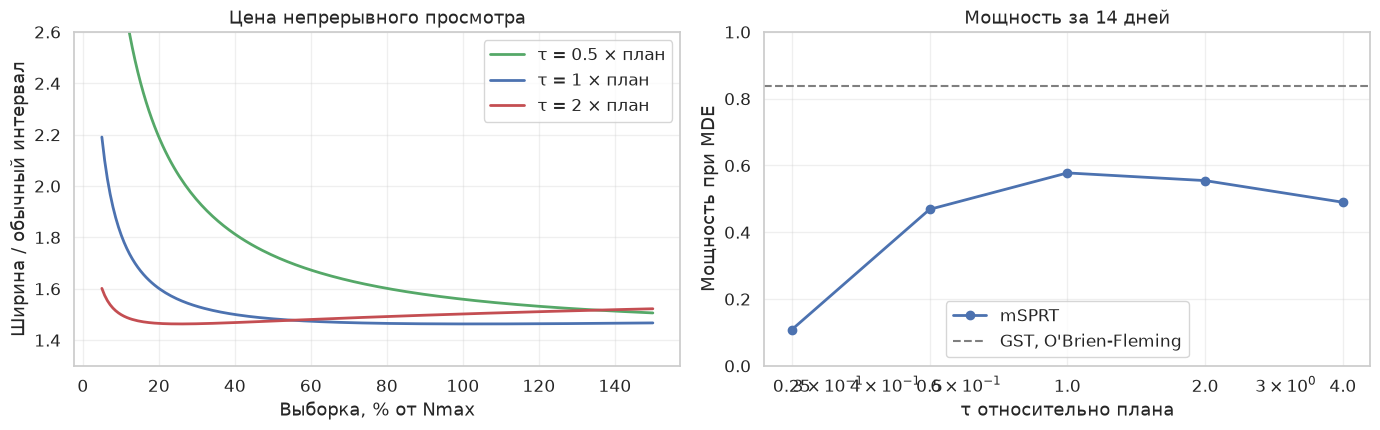

GST при MDE: мощность 0.839, средняя выборка 73.1% от Nmax; при 2 MDE — 38.8%
Ширина mSPRT / обычный интервал при Nmax и τ из плана: 1.46


,Мощность при MDE,Доля выборки при MDE,Доля выборки при 2 MDE,Ложных срабатываний
τ / τ по плану,,,,
0.250,0.108,0.989,0.686,0.000
0.500,0.469,0.882,0.436,0.001
1.000,0.578,0.796,0.327,0.005
2.000,0.555,0.786,0.297,0.006
4.000,0.490,0.815,0.307,0.005


In [14]:
def msprt_operating(tau_unit: float, drift: float, n_paths: int = 100_000, seed: int = 5) -> tuple:
    """Мощность и средняя доля выборки mSPRT с ежедневными взглядами до Nmax (единицы: V = 1/t)."""
    z = drift_paths(LOOKS, drift, n_paths, seed)
    diff = z / np.sqrt(LOOKS)                      # оценка эффекта в единицах sqrt(V_plan)
    hits = msprt_log_lambda(diff, 1 / LOOKS, tau_unit) >= np.log(1 / ALPHA_PRIMARY)
    fired = hits.any(axis=1)
    return float(fired.mean()), float(LOOKS[np.where(fired, hits.argmax(axis=1), len(LOOKS) - 1)].mean())


tau_ratios = np.array([0.25, 0.5, 1, 2, 4])
rows = {}
for ratio in tau_ratios:
    unit = ratio * TAU / np.sqrt(V_PLAN)
    (power_1, share_1), (_, share_2), (fpr, _) = (msprt_operating(unit, d) for d in (THETA_MDE, 2 * THETA_MDE, 0.0))
    rows[ratio] = {"Мощность при MDE": power_1, "Доля выборки при MDE": share_1,
                   "Доля выборки при 2 MDE": share_2, "Ложных срабатываний": fpr}
operating = pd.DataFrame(rows).T
operating.index.name = "τ / τ по плану"
gst_power_mde, gst_share_mde = gst_power(BOUNDS_OBF, LOOKS, THETA_MDE)
gst_share_2 = gst_power(BOUNDS_OBF, LOOKS, 2 * THETA_MDE)[1]

share = np.linspace(0.05, 1.5, 200)
V_curve = V_PLAN / share
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ratio, color in [(0.5, GREEN), (1, BLUE), (2, RED)]:
    axes[0].plot(share * 100, msprt_radius(V_curve, ratio * TAU) / (norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(V_curve)),
                 color=color, linewidth=2, label=f"τ = {ratio} × план")
axes[0].set(xlabel="Выборка, % от Nmax", ylabel="Ширина / обычный интервал", ylim=(1.3, 2.6), title="Цена непрерывного просмотра")
axes[0].legend()
axes[1].plot(tau_ratios, operating["Мощность при MDE"], "-o", color=BLUE, linewidth=2, label="mSPRT")
axes[1].axhline(gst_power_mde, color=GRAY, linestyle="--", linewidth=1.5, label="GST, O'Brien-Fleming")
axes[1].set(xscale="log", xticks=tau_ratios, xticklabels=tau_ratios, xlabel="τ относительно плана",
            ylabel="Мощность при MDE", ylim=(0, 1), title="Мощность за 14 дней")
axes[1].legend(loc="lower center")
plt.tight_layout()
plt.show()
print(f"GST при MDE: мощность {gst_power_mde:.3f}, средняя выборка {gst_share_mde:.1%} от Nmax; при 2 MDE — {gst_share_2:.1%}")
print(f"Ширина mSPRT / обычный интервал при Nmax и τ из плана: {msprt_radius(V_PLAN, TAU) / (norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(V_PLAN)):.2f}")
operating

* **Слева.** Интервал mSPRT шире обычного всегда; минимум ~1.46 обычной ширины — около планового объёма.
* **Справа.** Лучшая мощность при $\tau$ около плана, и она заметно ниже, чем у GST на той же выборке. Занижать $\tau$ вчетверо опасно, завышать — безопаснее.
* Ложных срабатываний около 0.5% при заявленных 2.5% — отсюда и часть потери мощности.

**Важно.** Always-valid гарантия — про **постоянный** эффект. Если эффект меняется (новизна), последовательность накрывает средний эффект на уже пришедших пользователях, а не будущий.

## Futility: остановка за бесперспективностью

GST останавливает тест, когда эффект доказан. Futility — когда доказать его **уже почти невозможно**: зачем жечь трафик ещё неделю, если его можно отдать следующей идее? Мерило — **условная мощность** (conditional power, CP): вероятность к концу теста пройти финальную границу $b_K$ при текущем $z_t$ и предположении об эффекте $\theta$ (снос в единицах $Z$ при $N_{max}$).

На шкале $B(t) = \sqrt{t} Z_t$ путь — броуновское движение со сносом $\theta$. Будущий прирост $B(1) - B(t)$ не зависит от прошлого и распределён нормально со средним $\theta(1-t)$ и дисперсией $1-t$. Отсюда

$$
\mathrm{CP}(\theta) = 1 - \Phi\left(\frac{b_K - \sqrt{t} z_t - \theta(1-t)}{\sqrt{1-t}}\right)
$$

Правило: если $\mathrm{CP} < \gamma$ (обычно $\gamma$ = 0.1–0.2), останавливаемся. Главный выбор — какое $\theta$ подставить:

* $\theta_{MDE}$ (**эффект из плана**) — «есть ли шанс поймать то, ради чего затевали тест»;
* $\hat\theta_t = z_t / \sqrt{t}$ (**текущий тренд**) — «будущее похоже на то, что видим сейчас».

Граница futility — значение $z_t$, при котором $\mathrm{CP}(\theta) = \gamma$: ниже неё — стоп.

In [15]:
def conditional_power(z_t, t, theta, final_bound):
    z_t = np.asarray(z_t, dtype=float)
    return norm.sf((final_bound - np.sqrt(t) * z_t - theta * (1 - t)) / np.sqrt(1 - t))


def futility_bound(t, theta, gamma, final_bound):
    return (final_bound - theta * (1 - t) - norm.isf(gamma) * np.sqrt(1 - t)) / np.sqrt(t)


FINAL_BOUND = BOUNDS_OBF[-1]

**Вопрос.** На 7-й день (половина данных) наблюдаемая z равна 0. Какой шанс у теста дойти до значимости — если верить плану и если верить текущему тренду? Какое правило вы бы взяли?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

По плану CP ≈ 0.15, по тренду — почти 0 (график ниже). Тренд при $z_t$ = 0 говорит «эффекта нет и не будет» и «хоронит» тест, который ещё мог вырасти до MDE: за оставшуюся половину данных снос $\theta_{MDE}$ добавит заметную часть пути.

Ранняя оценка шумная, а правило по тренду подставляет этот шум в будущее — и в плюс, и в минус. Поэтому для правила futility фиксируем $\theta$ из плана: оно отвечает на вопрос, ради которого затевали тест. Цену каждого правила посчитаем симуляцией после графика.

</details>

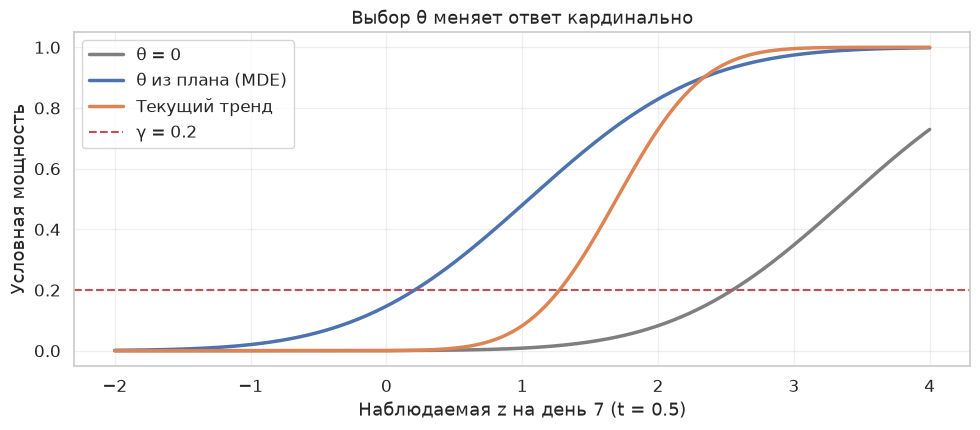

z = 0 на день 7: CP по плану 0.147, по тренду 0.000; граница futility (γ = 0.2, θ из плана): z < 0.21


In [16]:
z_grid = np.linspace(-2, 4, 300)
t_half = 0.5
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(z_grid, conditional_power(z_grid, t_half, 0.0, FINAL_BOUND), color=GRAY, linewidth=2.5, label="θ = 0")
ax.plot(z_grid, conditional_power(z_grid, t_half, THETA_MDE, FINAL_BOUND), color=BLUE, linewidth=2.5, label="θ из плана (MDE)")
ax.plot(z_grid, conditional_power(z_grid, t_half, z_grid / np.sqrt(t_half), FINAL_BOUND), color=ORANGE, linewidth=2.5,
        label="Текущий тренд")
ax.axhline(0.2, color=RED, linestyle="--", linewidth=1.5, label="γ = 0.2")
ax.set(xlabel="Наблюдаемая z на день 7 (t = 0.5)", ylabel="Условная мощность", title="Выбор θ меняет ответ кардинально")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"z = 0 на день 7: CP по плану {conditional_power(0.0, t_half, THETA_MDE, FINAL_BOUND):.3f}, "
      f"по тренду {conditional_power(0.0, t_half, 0.0, FINAL_BOUND):.3f}"
      f"; граница futility (γ = 0.2, θ из плана): z < {futility_bound(t_half, THETA_MDE, 0.2, FINAL_BOUND):.2f}")

Правило в нашем плане: **futility проверяем на днях 7 и 10; если $\mathrm{CP} < \gamma$ = 0.2 — останавливаемся**. Сравним три дизайна на 400 тыс. симулированных тестов: без futility, futility по эффекту из плана, futility по текущему тренду. «Запуск» — пересечение верхней границы; при $H_0$ это ложный запуск.

**Вопрос.** Futility добавляет к тесту ещё одно правило остановки. Не вырастет ли от этого ошибка I рода, как при подглядывании? А что с мощностью?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Ложных запусков futility не добавляет: она только **убирает** пути, которые и так вряд ли дошли бы до границы эффективности. Подглядывание опасно тем, что даёт шуму лишние шансы пройти порог в сторону «успеха»; futility таких шансов не даёт.

Платим мощностью: какие-то живые тесты правило всё-таки срежет. По таблице ниже правило по плану стоит 0.6 п.п. мощности и сокращает среднюю выборку при $H_0$ со 100% до 62% $N_{max}$. Правило по тренду экономит больше (53%), но теряет 7 п.п. мощности: ранний шум принимается за отсутствие эффекта.

</details>

In [17]:
FUTILITY_DAYS = (7, 10)
GAMMA = 0.2


def run_design(drift: float, futility: str = None, n_paths: int = 400_000, seed: int = 5) -> dict:
    """GST O'Brien-Fleming с ежедневными взглядами и futility на днях FUTILITY_DAYS: 'plan' — θ из плана, 'trend' — текущий тренд."""
    z = drift_paths(LOOKS, drift, n_paths, seed)
    alive = np.ones(n_paths, dtype=bool)
    win, futile = np.zeros(n_paths, dtype=bool), np.zeros(n_paths, dtype=bool)
    stop = np.full(n_paths, 1.0)
    for i, t in enumerate(LOOKS):
        zi = z[:, i]
        crossed = alive & (np.abs(zi) >= BOUNDS_OBF[i])
        win |= crossed & (zi > 0)
        stop[crossed] = t
        alive &= ~crossed
        if futility and i + 1 in FUTILITY_DAYS:
            theta = THETA_MDE if futility == "plan" else zi / np.sqrt(t)
            cut = alive & (conditional_power(zi, t, theta, FINAL_BOUND) < GAMMA)
            futile |= cut
            stop[cut] = t
            alive &= ~cut
    return {"Запуск": win.mean(), "Стоп по futility": futile.mean(), "Средняя выборка, % от Nmax": 100 * stop.mean()}


designs = {"GST без futility": None, "GST + futility, θ из плана": "plan", "GST + futility, текущий тренд": "trend"}
futility_table = pd.concat({"H0: эффекта нет": pd.DataFrame({k: run_design(0.0, v) for k, v in designs.items()}).T,
                            "Эффект = MDE": pd.DataFrame({k: run_design(THETA_MDE, v) for k, v in designs.items()}).T}, axis=1)
futility_table

H0: эффекта нет                   \
                                       Запуск Стоп по futility   
GST без futility                        0.013            0.000   
GST + futility, θ из плана              0.012            0.885   
GST + futility, текущий тренд           0.010            0.961   

                                                         Эффект = MDE  \
                              Средняя выборка, % от Nmax       Запуск   
GST без futility                                  99.532        0.838   
GST + futility, θ из плана                        61.981        0.832   
GST + futility, текущий тренд                     53.046        0.766   

                                                                           
                              Стоп по futility Средняя выборка, % от Nmax  
GST без futility                         0.000                     73.126  
GST + futility, θ из плана               0.058                     71.132  
GST + futility, текущий тренд            0.184                     65.438

**Binding или non-binding.** Можно ли проигнорировать стоп по futility и продолжить? Это зависит от того, как считались границы эффективности:

* **non-binding** — границы эффективности посчитаны так, будто futility нет. Стоп — рекомендация: отменить его можно без роста $\alpha$, а соблюдение лишь делает тест чуть консервативнее;
* **binding** — границы посчитаны на путях, переживших futility, поэтому они ниже и тест чуть мощнее. Стоп обязателен: если его проигнорировать, $\alpha$ превысит заявленную.

Проверим на верхней границе нашего плана: она тратит половину двустороннего бюджета, 1.25%, и на день 14 совпадает с `BOUNDS_OBF` (≈ 2.40). Границы и ошибку считаем на одних и тех же путях. Тогда у «правильных» вариантов 1.25% выходит точно по построению, а превышение — это ровно пути, которые futility остановила бы, а дальше они прошли бы границу. Для сравнения добавим агрессивное правило γ = 0.5.

**Вопрос.** Что выбрать в нашем тесте — binding или non-binding? Подумайте, как в продукте обычно реагируют на «стоп, тест бесперспективен».

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Non-binding.** В продукте стоп по futility отменяют часто: «давайте ещё посмотрим», «на следующей неделе распродажа». При non-binding это безопасно: $\alpha$ не растёт.

Выигрыш binding при нашем правиле — сотые доли границы: 2.38 против 2.40 на день 14. А нарушение binding-стопа систематически поднимает ошибку: при γ = 0.2 с 1.25% до 1.28%, при агрессивном γ = 0.5 — до 1.66%, на треть выше заявленной. Чем агрессивнее futility, тем больше binding выигрывает в границе и тем дороже нарушение.

</details>

In [18]:
def upper_bounds(z, futility_z: dict = None) -> np.ndarray:
    """Верхние границы O'Brien-Fleming: половина двустороннего расхода плана.
    futility_z = {номер взгляда: z-граница} — binding: считаем только на путях, переживших futility."""
    alive = np.ones(len(z), dtype=bool)
    spent, bounds = 0.0, []
    for i, t in enumerate(LOOKS):
        step = float(obf_spending(t, ALPHA_PRIMARY)) / 2 - spent
        spent += step
        values = z[alive, i]
        k = int(step * len(z))
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step)
        bounds.append(bound)
        alive[alive] = values < bound
        if futility_z and i in futility_z:
            alive &= z[:, i] >= futility_z[i]
    return np.array(bounds)


def false_rollout(z, bounds, futility_z: dict = None) -> np.ndarray:
    """Флаги путей H0, прошедших верхнюю границу; futility_z — если стоп соблюдается."""
    alive, win = np.ones(len(z), dtype=bool), np.zeros(len(z), dtype=bool)
    for i in range(len(LOOKS)):
        crossed = alive & (z[:, i] >= bounds[i])
        win |= crossed
        alive &= ~crossed
        if futility_z and i in futility_z:
            alive &= z[:, i] >= futility_z[i]
    return win


z0 = null_paths(LOOKS, 1_000_000, seed=11)   # одни пути и для границ, и для ошибки
rows = {}
for gamma in (GAMMA, 0.5):
    fut = {d - 1: futility_bound(LOOKS[d - 1], THETA_MDE, gamma, FINAL_BOUND) for d in FUTILITY_DAYS}
    nb, bd = upper_bounds(z0), upper_bounds(z0, fut)
    bd_kept, bd_ignored = false_rollout(z0, bd, fut), false_rollout(z0, bd)
    extra = (bd_ignored & ~bd_kept).mean()
    rows[f"γ = {gamma}"] = {"Futility, z на днях 7 / 10": f"{fut[6]:.2f} / {fut[9]:.2f}",
        "Граница дня 14: non-binding / binding": f"{nb[-1]:.3f} / {bd[-1]:.3f}",
        "Non-binding, соблюдаем, %": 100 * false_rollout(z0, nb, fut).mean(),
        "Non-binding, игнорируем, %": 100 * false_rollout(z0, nb).mean(),
        "Binding, соблюдаем, %": 100 * bd_kept.mean(),
        "Binding, игнорируем, %": 100 * bd_ignored.mean(),
        "Превышение, п.п.": 100 * extra, "SE превышения, п.п.": 100 * np.sqrt(extra / len(z0))}
binding_table = pd.DataFrame(rows).T
print(f"Заявленный ложный запуск (верхняя сторона) {100 * ALPHA_PRIMARY / 2:.2f}%")
binding_table

Заявленный ложный запуск (верхняя сторона) 1.25%


,"Futility, z на днях 7 / 10",Граница дня 14: non-binding / binding,"Non-binding, соблюдаем, %","Non-binding, игнорируем, %","Binding, соблюдаем, %","Binding, игнорируем, %","Превышение, п.п.","SE превышения, п.п."
γ = 0.2,0.21 / 1.18,2.396 / 2.378,1.220,1.248,1.248,1.280,0.031,0.002
γ = 0.5,1.05 / 1.72,2.396 / 2.217,1.034,1.248,1.248,1.664,0.416,0.006


При γ = 0.2 binding опускает последнюю границу всего на 0.02, а игнорирование стопа даёт +0.03 п.п. ошибки. Это мало, но систематически, а не шум: SE разницы 0.002 п.п. Non-binding зеркален: соблюдаем стоп — ошибка 1.22%, ниже заявленной. При γ = 0.5 граница binding уже 2.22, а нарушение стопа стоит 0.42 п.п.

Теперь наш лог. Посчитаем CP на днях 7 и 10 по фактическим данным (доля информации — фактическая).

In [19]:
cp_rows = {}
for d in FUTILITY_DAYS:
    row = cum_conv.loc[d]
    t = (row["n_a"] + row["n_b"]) / (2 * N_MAX)
    z_t = row["diff"] / np.sqrt(row["V"])
    cp_rows[f"День {d}"] = {"t": t, "z": z_t, "CP, θ из плана": conditional_power(z_t, t, THETA_MDE, FINAL_BOUND),
                            "CP, текущий тренд": conditional_power(z_t, t, z_t / np.sqrt(t), FINAL_BOUND),
                            "Граница futility": futility_bound(t, THETA_MDE, GAMMA, FINAL_BOUND)}
pd.DataFrame(cp_rows).T

,t,z,"CP, θ из плана","CP, текущий тренд",Граница futility
День 7,0.499,2.642,0.944,0.971,0.202
День 10,0.699,3.007,0.979,0.986,1.123


На обоих взглядах $z$ далеко выше границы futility, CP близка к 1: тест перспективный, продолжаем. CP по тренду ещё выше, потому что тренд на день 7 — около +0.6 п.п., больше MDE. Но это та же ранняя оценка, которая может быть завышена шумом и новизной (разделы 6 и 9), поэтому правило опирается на $\theta$ из плана.

## Прогон лога по дням

Функции `replay_gst` и `replay_msprt` проигрывают тест по дням. Доля данных в GST — **фактическая**, $(n_A + n_B) / (2N_{max})$: в выходные трафик выше. Границы пересчитываются по этим долям (гибкость Lan-DeMets), на последнем взгляде тратится весь остаток $\alpha$. По политике остановка **за успех — не раньше дня 7** (полный недельный цикл).

Выручку режем по порогу, зафиксированному до старта: 99-й перцентиль чека по истории, 196 тыс. ₽. Контрольную метрику проверяем mSPRT на рост: последовательность уровня 10% даёт одностороннюю гарантию 5%, тревога — нижняя граница выше нуля. Отмены считаем двумя способами: доля пользователей с отменой (guardrail из плана) и доля отмен среди броней.

In [20]:
MIN_DAY_SUCCESS = 7
logs["revenue_capped"] = logs["revenue"].clip(upper=CAP)
plan_logs = logs[logs["day"] <= PLAN_DAYS]


def history_revenue(n: int = 1_000_000, seed: int = 7) -> np.ndarray:
    """Выручка на пользователя до теста по истории: 4.8% броней, логнормальный чек с медианой 12 000 ₽."""
    rng = np.random.default_rng(seed)
    return (rng.random(n) < P_BASE) * np.minimum(rng.lognormal(np.log(12_000), 1.2, n), CAP)


def replay_gst(cum: pd.DataFrame, spending=obf_spending, n_max: int = N_MAX, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    share = ((cum["n_a"] + cum["n_b"]) / (2 * n_max)).clip(upper=1).to_numpy().copy()
    share[-1] = 1.0
    bounds = gst_boundaries(spending, share, alpha)
    z = (cum["diff"] / np.sqrt(cum["V"])).to_numpy()
    return cum.assign(share=share, z=z, bound=bounds, radius=bounds * np.sqrt(cum["V"]), crossed=np.abs(z) >= bounds)


def replay_msprt(cum: pd.DataFrame, tau: float, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    pvalue = always_valid_p(cum["diff"].to_numpy(), cum["V"].to_numpy(), tau)
    return cum.assign(p_always=pvalue, radius=msprt_radius(cum["V"], tau, alpha), crossed=pvalue <= alpha)


def first_day(result: pd.DataFrame, min_day: int = 1):
    """Первый день срабатывания не раньше min_day."""
    hit = result["crossed"] & (result.index >= min_day)
    return int(result.index[hit.argmax()]) if hit.any() else None


def summarize(name: str, method: str, result: pd.DataFrame, scale: float, min_day: int = 1) -> dict:
    day = first_day(result, min_day)
    row = result.loc[day] if day else result.iloc[-1]
    return {"Метрика": name, "Метод": method, "День остановки": day or "нет", "Оценка": row["diff"] * scale,
            "Нижняя граница": (row["diff"] - row["radius"]) * scale, "Верхняя граница": (row["diff"] + row["radius"]) * scale}


gst_conv = replay_gst(cum_conv)
msprt_conv = replay_msprt(cum_conv, TAU)
cum_rev = daily_cumulative(plan_logs, "revenue_capped")
TAU_REV = tau_from_plan(2 * history_revenue().var() / N_MAX)
gst_rev, msprt_rev = replay_gst(cum_rev), replay_msprt(cum_rev, TAU_REV)
TAU_CANCEL = tau_from_plan(2 * P_CANCEL * (1 - P_CANCEL) / N_MAX, alpha=2 * ALPHA)
msprt_cancel = replay_msprt(daily_cumulative(plan_logs, "cancelled"), TAU_CANCEL, alpha=2 * ALPHA)
msprt_cancel["crossed"] = msprt_cancel["diff"] - msprt_cancel["radius"] > 0
P_CANCEL_BOOKED = P_CANCEL / P_BASE          # доля отмен среди броней по истории
TAU_CANCEL_BOOKED = tau_from_plan(2 * P_CANCEL_BOOKED * (1 - P_CANCEL_BOOKED) / (N_MAX * P_BASE), alpha=2 * ALPHA)


def cancel_booked_msprt(df: pd.DataFrame) -> pd.DataFrame:
    """mSPRT на рост доли отмен среди броней (α = 10%, односторонняя гарантия 5%)."""
    r = replay_msprt(daily_cumulative(df[df["booked"] == 1], "cancelled"), TAU_CANCEL_BOOKED, alpha=2 * ALPHA)
    r["crossed"] = r["diff"] - r["radius"] > 0
    return r


msprt_cancel_booked = cancel_booked_msprt(plan_logs)

stop_day = first_day(gst_conv, MIN_DAY_SUCCESS)
harm_day = first_day(msprt_cancel)
replay = pd.DataFrame([summarize("Конверсия, п.п.", "GST", gst_conv, 100, MIN_DAY_SUCCESS),
                       summarize("Конверсия, п.п.", "mSPRT", msprt_conv, 100, MIN_DAY_SUCCESS),
                       summarize("Выручка с порогом, ₽", "GST", gst_rev, 1, MIN_DAY_SUCCESS),
                       summarize("Выручка с порогом, ₽", "mSPRT", msprt_rev, 1, MIN_DAY_SUCCESS),
                       summarize("Доля пользователей с отменой, п.п.", "mSPRT, рост (α = 10%)", msprt_cancel, 100),
                       summarize("Отмены среди броней, п.п.", "mSPRT, рост (α = 10%)", msprt_cancel_booked, 100)])
print(f"GST по конверсии: первое пересечение — день {first_day(gst_conv)}, остановка по политике — день {stop_day}"
      f"; guardrail по пользователям: тревога на день {harm_day}, среди броней: {first_day(msprt_cancel_booked) or 'нет'}")
replay

GST по конверсии: первое пересечение — день 8, остановка по политике — день 8; guardrail по пользователям: тревога на день 3, среди броней: 3


,Метрика,Метод,День остановки,Оценка,Нижняя граница,Верхняя граница
0,"Конверсия, п.п.",GST,8,0.658,0.037,1.278
1,"Конверсия, п.п.",mSPRT,11,0.593,0.026,1.160
2,"Выручка с порогом, ₽",GST,нет,83.131,-57.048,223.309
3,"Выручка с порогом, ₽",mSPRT,нет,83.131,-109.414,275.676
4,"Доля пользователей с отменой, п.п.","mSPRT, рост (α = 10%)",3,0.542,0.066,1.018
5,"Отмены среди броней, п.п.","mSPRT, рост (α = 10%)",3,8.546,0.025,17.067


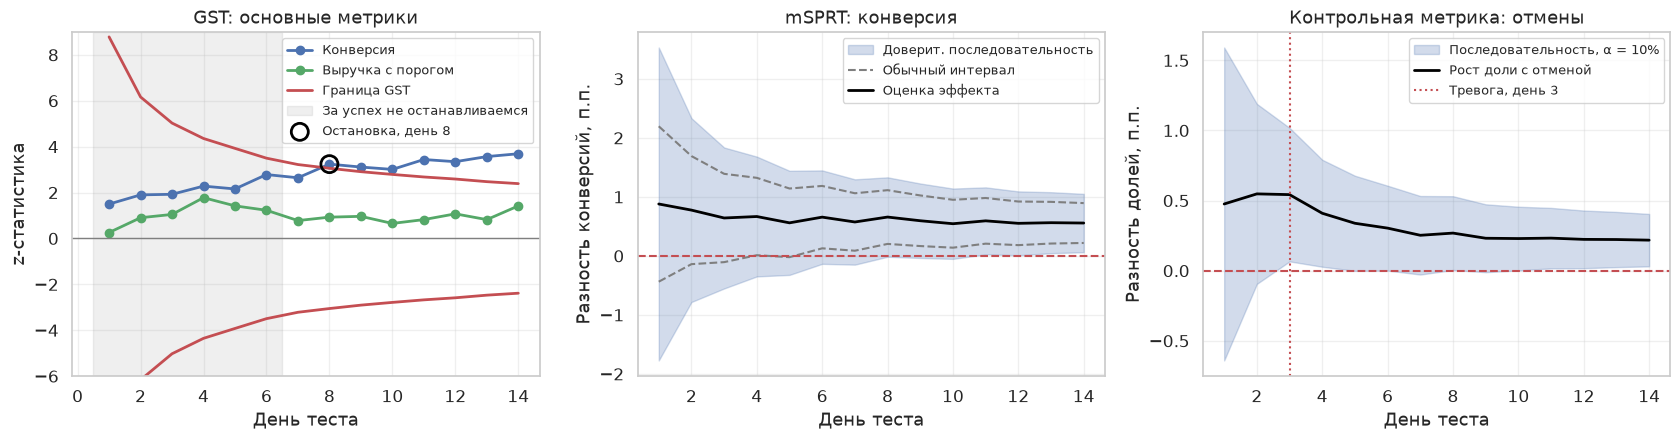

,share,diff,z,bound
day,,,,
7,0.499,0.006,2.642,3.218
8,0.566,0.007,3.237,3.056
9,0.633,0.006,3.109,2.907


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
d = gst_conv.index
axes[0].plot(d, gst_conv["z"], "-o", color=BLUE, linewidth=2, label="Конверсия")
axes[0].plot(d, gst_rev["z"], "-o", color=GREEN, linewidth=2, label="Выручка с порогом")
axes[0].plot(d, gst_conv["bound"], color=RED, linewidth=2, label="Граница GST")
axes[0].plot(d, -gst_conv["bound"], color=RED, linewidth=2)
axes[0].axvspan(0.5, MIN_DAY_SUCCESS - 0.5, color=GRAY, alpha=0.12, label="За успех не останавливаемся")
axes[0].axhline(0, color=GRAY, linewidth=1)
axes[0].scatter([stop_day], [gst_conv.loc[stop_day, "z"]], s=150, facecolor="none", edgecolor="black", linewidth=2, zorder=4,
                label=f"Остановка, день {stop_day}")
axes[0].set(xlabel="День теста", ylabel="z-статистика", ylim=(-6, 9), title="GST: основные метрики")
axes[0].legend(fontsize=9, loc="upper right")

fixed = norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(msprt_conv["V"])
axes[1].fill_between(d, 100 * (msprt_conv["diff"] - msprt_conv["radius"]), 100 * (msprt_conv["diff"] + msprt_conv["radius"]),
                     color=BLUE, alpha=0.25, label="Доверит. последовательность")
axes[1].plot(d, 100 * (msprt_conv["diff"] - fixed), color=GRAY, linestyle="--", linewidth=1.5, label="Обычный интервал")
axes[1].plot(d, 100 * (msprt_conv["diff"] + fixed), color=GRAY, linestyle="--", linewidth=1.5)
axes[1].plot(d, 100 * msprt_conv["diff"], color="black", linewidth=2, label="Оценка эффекта")
axes[1].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Разность конверсий, п.п.", title="mSPRT: конверсия")
axes[1].legend(fontsize=9)

axes[2].fill_between(d, 100 * (msprt_cancel["diff"] - msprt_cancel["radius"]), 100 * (msprt_cancel["diff"] + msprt_cancel["radius"]),
                     color=BLUE, alpha=0.25, label="Последовательность, α = 10%")
axes[2].plot(d, 100 * msprt_cancel["diff"], color="black", linewidth=2, label="Рост доли с отменой")
axes[2].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[2].axvline(harm_day, color=RED, linestyle=":", linewidth=1.5, label=f"Тревога, день {harm_day}")
axes[2].set(xlabel="День теста", ylabel="Разность долей, п.п.", title="Контрольная метрика: отмены")
axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()
gst_conv.loc[stop_day - 1: stop_day + 1, ["share", "diff", "z", "bound"]]

На 8-й день конверсия пересекла границу GST: $z$ = 3.24 при границе 3.06. mSPRT по конверсии срабатывает позже, на 11-й день — плата за always-valid гарантию. Выручка значимо не меняется ни по одному методу. Guardrail из плана поднимает тревогу уже на 3-й день, к нему вернёмся в разделе «Решение для продакта».

## Завышение эффекта при ранней остановке и честный отчёт

Оценка на день остановки — около **+0.66 п.п.**, на треть выше MDE. Продакт пишет: «Конверсия +14%, раскатываем!»

**Вопрос.** Метод корректный, $\alpha$ под контролем, граница честно пройдена. Можно ли верить оценке +0.66 п.п.?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Честная остановка контролирует ошибку **решения** («эффект есть»), но не точность оценки. Рано пройти высокую границу O'Brien-Fleming можно только с большой оценкой, и чаще всего её даёт шум, подыгравший эффекту. Отбирая тесты по факту пересечения, мы отбираем завышенные оценки.

Симуляция ниже, в чистых условиях (эффект постоянный, без новизны): если эффект равен MDE и тест остановился до 8-го дня включительно, оценка в среднем завышена в 1.6 раза; если эффект вдвое меньше MDE — почти втрое. По всем тестам вместе смещение скромное, но на столе у нас именно рано остановленный тест. А в наших данных есть ещё и новизна (раздел 9).

</details>

Функция `stopped_estimates` останавливает каждый путь на первом $|Z| \ge b_i$ и возвращает день остановки, флаг срабатывания и отношение оценки в момент остановки к истинному эффекту. Эффект задаётся в долях MDE.

In [22]:
def stopped_estimates(effect: float, boundaries=BOUNDS_OBF, looks=LOOKS, n_paths: int = 400_000, seed: int = 3) -> tuple:
    drift = effect * THETA_MDE
    z = drift_paths(looks, drift, n_paths, seed)
    estimates = z / np.sqrt(looks)                 # B(t) / t
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    last = np.where(fired, hits.argmax(axis=1), len(looks) - 1)
    return last + 1, fired, estimates[np.arange(n_paths), last] / drift


rows, cache = [], {}
for effect in (0.5, 1.0, 1.5):
    stop_look, fired, ratio = cache[effect] = stopped_estimates(effect)
    early = fired & (stop_look <= 8)
    rows.append({"Эффект, MDE": effect, "Мощность": fired.mean(), "Завышение, все тесты": ratio.mean(),
                 "Завышение, значимые": ratio[fired].mean(), "Доля остановок до дня 8": early.mean(),
                 "Завышение, остановки до дня 8": ratio[early].mean()})
overestimation = pd.DataFrame(rows).set_index("Эффект, MDE")
overestimation

,Мощность,"Завышение, все тесты","Завышение, значимые",Доля остановок до дня 8,"Завышение, остановки до дня 8"
"Эффект, MDE",,,,,
0.500,0.263,1.076,2.028,0.041,2.950
1.000,0.839,1.103,1.210,0.309,1.567
1.500,0.996,1.077,1.080,0.773,1.178


Обычный интервал вокруг такой оценки тоже смещён. Функция `coverage_at_stop` считает, как часто интервал в момент остановки накрывает истинный эффект (заявлено 97.5%): обычный интервал, **повторный доверительный интервал GST** $\hat\Delta \pm b_i \sqrt{V}$ и последовательность mSPRT.

In [23]:
def coverage_at_stop(effect: float = 1.0, max_day: int = PLAN_DAYS) -> pd.Series:
    stop_look, fired, ratio = cache[effect]
    chosen = fired & (stop_look <= max_day)
    t = LOOKS[stop_look - 1]
    error = np.abs(ratio - 1) * effect * THETA_MDE
    half_naive = norm.ppf(1 - ALPHA_PRIMARY / 2) / np.sqrt(t)
    half_gst = BOUNDS_OBF[stop_look - 1] / np.sqrt(t)
    half_msprt = msprt_radius(1 / t, TAU / np.sqrt(V_PLAN))
    return pd.Series({"Обычный интервал": (error <= half_naive)[chosen].mean(),
                      "Повторный интервал GST": (error <= half_gst)[chosen].mean(),
                      "Последовательность mSPRT": (error <= half_msprt)[chosen].mean()})


coverage = pd.DataFrame({**{f"{e} MDE, все остановки": coverage_at_stop(e) for e in (0.5, 1.0)},
                         **{f"{e} MDE, до дня 8": coverage_at_stop(e, 8) for e in (0.5, 1.0)}})
coverage.T

,Обычный интервал,Повторный интервал GST,Последовательность mSPRT
"0.5 MDE, все остановки",0.928,0.999,0.998
"1.0 MDE, все остановки",0.980,1.000,1.000
"0.5 MDE, до дня 8",0.561,0.997,0.987
"1.0 MDE, до дня 8",0.947,1.000,0.999


Среди ранних остановок обычный интервал теряет покрытие: при эффекте 0.5 MDE и остановке до дня 8 — 56% вместо 97.5%. Повторный интервал GST и последовательность mSPRT держат уровень при любом дне остановки. В отчёте показываем их.

**Честный отчёт** на день остановки по конверсии, в п.п.: точечная оценка, повторный интервал GST и последовательность mSPRT.

In [24]:
g, m = gst_conv.loc[stop_day], msprt_conv.loc[stop_day]
honest = {"estimate": 100 * g["diff"],
          "gst_low": 100 * (g["diff"] - g["radius"]), "gst_high": 100 * (g["diff"] + g["radius"]),
          "msprt_low": 100 * (m["diff"] - m["radius"]), "msprt_high": 100 * (m["diff"] + m["radius"])}
print(f"День {stop_day}: оценка {honest['estimate']:+.2f} п.п., повторный интервал GST [{honest['gst_low']:+.2f}; {honest['gst_high']:+.2f}], "
      f"mSPRT [{honest['msprt_low']:+.2f}; {honest['msprt_high']:+.2f}]")

День 8: оценка +0.66 п.п., повторный интервал GST [+0.04; +1.28], mSPRT [-0.02; +1.33]


Отчёт на 8-й день звучит так: «эффект на конверсию есть, повторный 97.5%-интервал — от +0.04 до +1.28 п.п.», а не «+0.66 п.п., +14%». Интервал сразу показывает, как мало мы знаем о размере эффекта: от «почти ноль» до «в 2.5 раза больше MDE».

## Решение для продакта

Блок проработал 28 дней — откроем весь лог. Интервалы ниже — доверительные последовательности mSPRT: они корректны на любой день. Для отмен две метрики: доля пользователей с отменой (guardrail из плана) и доля отмен **среди броней** — последовательно (mSPRT) и обычным односторонним p без поправки.

**Вопрос.** Guardrail из плана — доля пользователей с отменой — поднял тревогу на 3-й день. Значит ли это, что блок увеличивает отмены?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Не обязательно. Доля пользователей с отменой = конверсия × доля отмен среди броней. Она растёт при **любом** росте конверсии, даже если каждая бронь отменяется не чаще прежнего. К дню 28 прирост этой доли +0.14 п.п., и около половины его — просто больше броней: +0.35 п.п. конверсии × ~19% ≈ +0.07 п.п. Такой guardrail механически конфликтует с основной метрикой: успешный тест сам себе запрещает раскатку.

Решающий вопрос — выросла ли доля отмен **среди броней** (таблица ниже). Последовательная проверка по ней срабатывает только на 3-й день и на волоске: нижняя граница +0.03 п.п. при интервале до +17 п.п. и ~400 бронях на группу. С 4-го дня ноль снова внутри последовательности и больше из неё не выходит. Результат чувствителен к $\tau$: при плановой доле отмен 18% вместо 18.75% тревоги нет. Обычный односторонний p — 0.052 на день 8 и 0.043 на день 28, без поправки и при ежедневном подглядывании. Сигнал пограничный: вред не доказан, но и не исключён.

Урок для политики: guardrail не должен расти вместе с основной метрикой, и первый взгляд на него — не раньше, чем наберётся достаточно событий (например, 1 000 броней на группу, около 7 дней).

</details>

In [25]:
def status(result: pd.DataFrame, day: int, scale: float) -> str:
    row = result.loc[day]
    return f"{row['diff'] * scale:+.2f} [{(row['diff'] - row['radius']) * scale:+.2f}; {(row['diff'] + row['radius']) * scale:+.2f}]"


fmt_p = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"


def cancel_among_bookings(df: pd.DataFrame) -> str:
    booked = df[df["booked"] == 1].groupby("group")["cancelled"].agg(["mean", "size"])
    diff = booked.loc["B", "mean"] - booked.loc["A", "mean"]
    se = np.sqrt((booked["mean"] * (1 - booked["mean"]) / booked["size"]).sum())
    return f"{100 * booked.loc['A', 'mean']:.1f}% → {100 * booked.loc['B', 'mean']:.1f}% (p {"< 0.001" if norm.sf(diff / se) < 0.001 else f"= {norm.sf(diff / se):.3f}"})"


full_conv = replay_msprt(daily_cumulative(logs, "booked"), TAU)
full_rev = replay_msprt(daily_cumulative(logs, "revenue_capped"), TAU_REV)
full_cancel = replay_msprt(daily_cumulative(logs, "cancelled"), TAU_CANCEL, alpha=2 * ALPHA)
full_cancel_booked = cancel_booked_msprt(logs)
report = pd.DataFrame({f"День {d}": {
    "Конверсия, п.п.": status(full_conv, d, 100),
    "Выручка с порогом, ₽": status(full_rev, d, 1),
    "Доля пользователей с отменой, п.п. (α = 10%)": status(full_cancel, d, 100),
    "Доля пользователей с отменой: односторонний p": fmt_p(norm.sf(full_cancel.loc[d, 'diff'] / np.sqrt(full_cancel.loc[d, 'V']))),
    "Отмены среди броней, п.п. (mSPRT, α = 10%)": status(full_cancel_booked, d, 100),
    "Отмены среди броней: A → B, обычный p": cancel_among_bookings(logs[logs["day"] <= d]),
} for d in (harm_day, stop_day, 14, 28)})
print(f"Отмены среди броней, mSPRT: максимум нижней границы за 28 дней {100 * (full_cancel_booked['diff'] - full_cancel_booked['radius']).max():+.3f} п.п. "
      f"(день {int((full_cancel_booked['diff'] - full_cancel_booked['radius']).idxmax())}); дни тревоги: {list(full_cancel_booked.index[full_cancel_booked['crossed']]) or 'нет'}")
tau_18 = tau_from_plan(2 * 0.18 * 0.82 / (N_MAX * P_BASE), alpha=2 * ALPHA)
r18 = replay_msprt(daily_cumulative(logs[logs["booked"] == 1], "cancelled"), tau_18, alpha=2 * ALPHA)
print(f"Плановая доля отмен 18% вместо {P_CANCEL_BOOKED:.2%}: нижняя граница на день {harm_day} — "
      f"{100 * (r18.loc[harm_day, 'diff'] - r18.loc[harm_day, 'radius']):+.3f} п.п.")
report

Отмены среди броней, mSPRT: максимум нижней границы за 28 дней +0.025 п.п. (день 3); дни тревоги: [3]
Плановая доля отмен 18% вместо 18.75%: нижняя граница на день 3 — -0.021 п.п.


,День 3,День 8,День 14,День 28
"Конверсия, п.п.",+0.64 [-0.55; +1.84],+0.66 [-0.02; +1.33],+0.56 [+0.06; +1.05],+0.35 [-0.00; +0.70]
"Выручка с порогом, ₽",+135.73 [-327.91; +599.36],+73.77 [-189.82; +337.36],+83.13 [-109.41; +275.68],-8.17 [-143.30; +126.95]
"Доля пользователей с отменой, п.п. (α = 10%)",+0.54 [+0.07; +1.02],+0.27 [+0.00; +0.53],+0.22 [+0.03; +0.40],+0.14 [+0.01; +0.28]
Доля пользователей с отменой: односторонний p,<0.001,0.002,<0.001,0.002
"Отмены среди броней, п.п. (mSPRT, α = 10%)",+8.55 [+0.03; +17.07],+2.62 [-1.90; +7.15],+2.20 [-1.15; +5.55],+1.48 [-0.93; +3.89]
"Отмены среди броней: A → B, обычный p",15.1% → 23.6% (p < 0.001),18.8% → 21.4% (p = 0.052),18.1% → 20.3% (p = 0.035),18.7% → 20.2% (p = 0.043)


In [26]:
cohort = (logs["day"] - 1) // 7 + 1
weekly = logs.groupby([cohort, "group"])["booked"].mean().unstack()
pd.DataFrame({"Оценка по когорте, п.п.": 100 * (weekly["B"] - weekly["A"]).values,
              "Накопленная оценка на конец недели, п.п.": [100 * full_conv.loc[d, "diff"] for d in (7, 14, 21, 28)]},
             index=["дни 1–7", "дни 8–14", "дни 15–21", "дни 22–28"]).round(2)

,"Оценка по когорте, п.п.","Накопленная оценка на конец недели, п.п."
дни 1–7,0.570,0.570
дни 8–14,0.540,0.560
дни 15–21,0.100,0.410
дни 22–28,0.180,0.350


Оценки по недельным когортам: около +0.55 п.п. в первые две недели и +0.1–0.2 п.п. в третью и четвёртую. Накопленная оценка ползёт вниз вслед за ними. Недели 3–4 лежат за $N_{max}$ и поэтому разведочные, но для решения о раскатке это главный сигнал.

**Вопрос.** Напишите продакту 3–5 предложений: что с метриками, раскатываем ли блок, что дальше.

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Конверсия.** Рост есть, но оценка дня остановки (+0.66 п.п.) завышена: к дню 28 накопленная оценка опускается до +0.35 п.п., а поздние когорты слабее ранних.
* **Выручка.** Значимого роста нет ни на одном взгляде; вероятно, скидки съедают прирост броней.
* **Отмены.** Guardrail из плана сработал на 3-й день, и по правилу раскатка с этого дня запрещена. Но он растёт вместе с конверсией. Отмены среди броней скорее выше (18.7% → 20.2% к дню 28, p ≈ 0.04 без поправки), а последовательная проверка по ним сработала лишь раз, на 3-й день. Без правила минимума событий эта тревога тоже запретила бы раскатку, но она пришла на ~400 бронях на группу и дальше не повторилась. Отсюда правило: первый взгляд на guardrail — после 1 000 броней на группу (около 7 дней); с ним тревоги нет.

**Решение: блок в текущем виде не раскатываем.** Формально — по правилу, зафиксированному до старта: контрольная метрика из плана значимо ухудшилась, а правила после старта не меняют. Но опираться на один этот сигнал нельзя: он вырос бы при любом успехе. По существу решение держится на трёх вещах: выручка не растёт, эффект на конверсию затухает по когортам, отмены среди броней скорее выше, чем ниже.

Дальше: разобраться с глубиной скидок и запустить новый тест на две недели. Guardrail в нём — доля отмен среди броней с mSPRT после 1 000 броней на группу; в журнал — урок про guardrail по пользователям.

</details>

## Политика остановки

Итог встречи — политика остановки по шаблону `stopping_policy.md`. Заполняйте её так, как заполнили бы **до старта**: числа плана — из разделов про GST, mSPRT и futility. То, что узнали из лога (продление до 28 дней, неудачный guardrail), — в журнал отклонений (раздел 8 шаблона). Пример для «Горящих предложений» — ниже; свой тест заполните после встречи.

<details>
<summary><b>Пример заполнения</b> (нажмите, чтобы раскрыть)</summary>

**1. Тест и метрики.** «Горящие предложения» на главной; единица — пользователь, момент входа — первый заход на главную. Основные: конверсия в бронирование и выручка на пользователя (порог 196 тыс. ₽, зафиксирован по истории), $\alpha$ = 2.5% на каждую (двусторонний). Guardrail: доля отмен среди броней, mSPRT после 1 000 броней на группу, тревога при одностороннем 5%. Не доля пользователей с отменой: она растёт вместе с конверсией. MDE +0.5 п.п. при базе 4.8%. Фиксированный тест — 36.5 тыс. на группу, 12.2 дня. Раскатываем, если значимо выросла хотя бы одна основная метрика и guardrail значимо не ухудшился.

**2. Расписание.** Продакт смотрит дашборд каждый день, на дашборде только повторные интервалы. Взгляды по эффективности — ежедневно, дни 1–14; доля информации — по факту. Futility — дни 7 и 10. Guardrail (отмены среди броней) — mSPRT каждый день, но первый взгляд — после 1 000 броней на группу (около 7 дней): на меньшем числе броней тревога — ранний шум.

**3. Эффективность.** GST, O'Brien-Fleming: $N_{max}$ известен, взглядов 14. Запас $R \approx 1.05$, округлено до двух недель: $N_{max}$ = 42 000 на группу. Границы для |Z|: 8.4 в день 1, 3.2 в день 7, 2.4 в день 14. Мощность при MDE ≈ 84%.

**4. Futility.** $\mathrm{CP}(\theta_{MDE}) < 0.2$ на днях 7 и 10, то есть $z$ < 0.21 на день 7 и $z$ < 1.18 на день 10 (по плановым долям; по факту пересчитываем). Non-binding. При $H_0$ средняя выборка — 62% $N_{max}$ вместо 100%; потеря мощности при MDE ≈ 0.6 п.п.

**5. Длительность.** За успех — не раньше дня 7. Пересечения до дня 7 не считаются: успех — первый день $d \ge 7$, на котором $|z_d|$ выше границы дня $d$. Ранние пересечения игнорируем; это консервативно, $\alpha$ не растёт. За вред — в любой день. Перед решением — эффект по недельным когортам. Нет пересечения к дню 14 — тест закрыт: «эффект ≥ MDE маловероятен, меньший не исключён». За день 14 не продлеваем.

**6. Матрица эскалации.**

| Ситуация | Сигнал | Действие | Кто решает | Срок |
| --- | --- | --- | --- | --- |
| Успех | граница пройдена, день ≥ 7, guardrail чистые | стоп; отчёт с повторным интервалом и когортами; раскатка с holdout 5% на месяц | продакт по отчёту аналитика | 1 день |
| Вред по guardrail | последовательность по отменам среди броней исключает ноль | эскалация владельцу метрики; раскатка запрещена; тест на паузу или продолжаем только для диагностики | владелец guardrail + продакт | в тот же день |
| Вред по основной | пройдена нижняя граница | стоп, откат, разбор | продакт | в тот же день |
| «Ничего не происходит» | futility или день 14 без пересечения | стоп; отчёт с интервалом; идея — на доработку или в архив | продакт | 1 день |
| Проблемы с данными | SRM, сбой логирования | пауза; чек-лист встречи 3; дни со сбоем — в журнал | аналитик | в тот же день |
| «Ещё неделю» | просьба продлить за день 14 | нет; новый тест с новым планом или результат «разведочный» | аналитик | — |

**7. Отчёт.** «День 8 ($t$ = 0.57), $z$ = 3.24 при границе 3.06. Эффект на конверсию есть: повторный 97.5%-интервал от +0.04 до +1.28 п.п.; точечная оценка +0.66 п.п. завышена ранней остановкой. Guardrail из плана (доля пользователей с отменой): тревога с дня 3, раскатка запрещена правилом. Он механически связан с конверсией. Отмены среди броней: последовательная проверка сработала лишь на 3-й день на волоске (нижняя граница +0.03 п.п.) и дальше не повторилась, обычный p ≈ 0.05; сигнал пограничный, мощность низкая. Без правила минимума событий эта тревога тоже запретила бы раскатку, но она пришла на ~400 бронях на группу и дальше не повторилась. Отсюда правило: первый взгляд на guardrail — после 1 000 броней на группу (около 7 дней); с ним тревоги нет. Отклонение: тест шёл 28 дней при плане 14 (заморозка релизов). Вывод по конверсии сделан на день 8 по плановым границам. Дни 15–28 и когорты — разведочные: продление за $N_{max}$ политикой запрещено (раздел 5)».

Итог: раскатка запрещена guardrail-правилом; по существу — выручка не растёт и эффект затухает.

**8. Журнал.**

- Отклонение от раздела 5: блок проработал 28 дней вместо 14 из-за заморозки релизов. Решение — по дню 8; дни 15–28 — только разведочный анализ когорт, статус «разведочный».
- Guardrail в плане был по пользователям и растёт вместе с конверсией; в политике и следующем тесте — доля отмен среди броней (mSPRT).

</details>

## Как было на самом деле

> **Только для разбора.** Ниже — истинные параметры генератора данных. В реальном тесте их не узнать; здесь они нужны, чтобы проверить выводы.

**Вопрос.** Повторный интервал на день 8 — от +0.04 до +1.28 п.п., накопленная оценка к дню 28 — +0.35 п.п. Как вы думаете, какой эффект блок даст через полгода? И какие инструменты встречи защищают от ошибки в эту сторону, а какие нет?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

По генератору долгосрочный эффект **+0.2 п.п.**, в 2.5 раза меньше MDE: оценка дня остановки завышает его в 3.3 раза. Здесь сложились две причины.

* **Отбор ранней остановки** (раздел 6). Против него работают повторный интервал в отчёте и минимальная длительность.
* **Новизна**: первые пользователи реагируют на блок сильнее, эффект затухает за 1–2 недели. Против неё никакая поправка $\alpha$ не помогает: GST и mSPRT честно отвечают на вопрос «есть ли эффект на уже пришедших», но не превращают реакцию первых пользователей в реакцию будущих. Помогают только полный недельный цикл до первой остановки за успех, анализ по непересекающимся когортам (недели прихода) перед решением и holdout после раскатки.

</details>

Истинный эффект на конверсию для когорты дня $d$ — новизна, которая затухает за 1–2 недели, поверх долгосрочных +0.2 п.п.:

$$
\Delta(d) = 0.2 + 0.8 e^{-(d-1)/4}
$$

(в п.п.). Брони в B на 5% дешевле из-за скидок. Доля отмен среди броней выросла с 18% до 19.5%.

In [27]:
def true_effect(day):
    """Истинный эффект на конверсию для когорты дня day (с 1) — из генератора данных."""
    return 0.002 + 0.008 * np.exp(-(np.asarray(day) - 1) / 4)


pd.DataFrame({"Оценка по когорте, п.п.": 100 * (weekly["B"] - weekly["A"]).values,
              "Истина, п.п.": [100 * true_effect(np.arange(a, a + 7)).mean() for a in (1, 8, 15, 22)],
              "Накопленная оценка на конец недели, п.п.": [100 * full_conv.loc[d, "diff"] for d in (7, 14, 21, 28)]},
             index=["дни 1–7", "дни 8–14", "дни 15–21", "дни 22–28"]).round(2)

,"Оценка по когорте, п.п.","Истина, п.п.","Накопленная оценка на конец недели, п.п."
дни 1–7,0.570,0.630,0.570
дни 8–14,0.540,0.270,0.560
дни 15–21,0.100,0.210,0.410
дни 22–28,0.180,0.200,0.350


Истина подтверждает то, что когортный анализ в разделе 7 показал без знания генератора: эффект ранних когорт — новизна, долгосрочный — около +0.2 п.п.

## Итоги

* Ежедневный взгляд в обычный тест — около 22% ложных срабатываний вместо 5% (при $\alpha$ = 2.5% — 12% вместо 2.5%).
* GST с O'Brien-Fleming разрешает смотреть каждый день за запас выборки ~5% (Pocock — ~25%). Наш план: 14 дней, $N_{max}$ = 42 000 на группу. За $N_{max}$ не выходим.
* mSPRT не требует $N_{max}$, $\tau$ берём из плана (около MDE); платим шириной (×1.46) и мощностью. Ему место на guardrail и в тестах с неизвестной длительностью.
* Futility по условной мощности при эффекте из плана экономит ~40% выборки при $H_0$ и почти не стоит мощности; делаем non-binding.
* Ранняя остановка завышает оценку; в отчёт — повторный интервал, а не точечная оценка.
* Статистически честная остановка не гарантирует верного продуктового решения: смотрим guardrail, когорты и минимальную длительность.

Артефакт встречи — политика остановки `stopping_policy.md` (пример — в разделе «Политика остановки»). На встрече 6 на этих же данных разберём сегменты и мемо.